# 01 - Data cleaning and Exploratory Data Analysis (EDA)

**Goal:** check the raw data for problems, fix them (explaining why each fix is made), and then understand
what drives monthly demand before building any model.

**Data:** `data/demand_panel.csv` - one row = one region in one month. There should be 6 regions x 48 months
(Jan 2021 - Dec 2024) = 288 rows.

| Column | Meaning | Unit |
|---|---|---|
| `date` | Month (first day of month) | - |
| `region` | Sales region | - |
| `price_usd_per_ton` | Our average selling price | USD / ton |
| `competitor_price_usd_per_ton` | Competitor average price | USD / ton |
| `promo_flag` | 1 if a promotion ran that month | 0 / 1 |
| `industrial_index` | Industrial production index (base = 100) | index |
| `demand_tons` | Units sold - **the target** | tons |
| `monthly_capacity_tons` | Plant capacity ceiling | tons |

**Plan**
- Sections 2-3: look at the raw data and find the problems (data quality checks).
- Section 4: fix them one by one and save `data/panel_clean.csv`.
- Sections 5-14: EDA on the cleaned data - region-wise vs overall, trend, seasonality, price, promotions,
  competitor, economy, capacity.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Load the raw data

In [2]:
raw = pd.read_csv("data/demand_panel.csv", parse_dates=["date"])

print("Rows x columns:", raw.shape)
print("Expected rows : 6 regions x 48 months =", 6 * 48)
raw.head(10)

Rows x columns: (291, 8)
Expected rows : 6 regions x 48 months = 288


,date,region,price_usd_per_ton,competitor_price_usd_per_ton,promo_flag,industrial_index,demand_tons,monthly_capacity_tons
0,2024-01-01,West,887.31,"1,110.94",0.00,106.54,"16,085.90","15,900.00"
1,2024-02-01,Gulf Coast,"1,023.71",926.17,0.00,110.02,"25,240.20","25,200.00"
2,2023-03-01,Midwest,"1,153.83",990.03,0.00,106.27,"11,893.30","13,300.00"
3,2022-01-01,Midwest,"1,156.56",987.24,0.00,104.21,"9,271.90","13,300.00"
4,2024-05-01,Midwest,"1,033.41","1,028.45",0.00,108.56,"14,171.00","13,300.00"
5,2021-04-01,West,990.43,"1,089.15",1.00,102.17,"12,776.50","15,900.00"
6,2024-01-01,Midwest,"1,120.97","1,023.49",1.00,107.36,"13,433.60","13,300.00"
7,2021-07-01,West,954.04,"1,170.12",0.00,101.73,"11,118.50","15,900.00"
8,2021-03-01,Gulf Coast,"1,000.53","1,036.04",0.00,101.75,"22,205.10","25,200.00"
9,2024-11-01,Midwest,992.99,"1,077.72",0.00,109.90,"13,253.70","13,300.00"


**What we see**
- 291 rows instead of the expected 288, so some rows are extra (duplicates or mislabelled).
- Rows are not in date order (2024, 2023, 2022 mixed together). We sort them during cleaning.
- `promo_flag` is read as a decimal (0.00 / 1.00) rather than 0/1. That usually means the column has blanks, which we check in 3.4.

## 3. Data quality checks

Before any analysis we check the things that commonly go wrong in real data:
labels, duplicates, missing months, missing values, wrong values (outliers).

### 3.1 Region names

In [3]:
# repr() shows hidden characters such as trailing spaces
for name, count in raw["region"].value_counts().items():
    print(f"{repr(name):16} {count} rows")

'Northeast'      49 rows
'Southeast'      48 rows
'West'           47 rows
'Midwest'        47 rows
'Great Lakes'    46 rows
'Gulf Coast'     40 rows
'great lakes'    8 rows
'Gulf Coast '    6 rows


**Problem found:** 8 spellings for 6 regions.
- `'Gulf Coast '` has a **trailing space** (6 rows).
- `'great lakes'` is **lowercase** (8 rows).

Python treats these as different regions, so any group-by would split them.

### 3.2 Plant capacity per region

Capacity is a property of the plant, so each region should always show the same capacity.
(Region names are tidied up here only for the check.)

In [4]:
region_tidy = raw["region"].str.strip().str.title()
pd.crosstab(region_tidy, raw["monthly_capacity_tons"])

monthly_capacity_tons,"11,200.00","11,500.00","13,300.00","15,900.00","17,600.00","25,200.00"
region,,,,,,
Great Lakes,49,0,2,1,0,2
Gulf Coast,0,0,0,0,0,46
Midwest,0,0,47,0,0,0
Northeast,0,49,0,0,0,0
Southeast,0,0,0,0,48,0
West,0,0,0,47,0,0


**Problem found**
- Five regions show exactly **one** capacity each, as expected.
- **Great Lakes** shows four different capacities: 49 rows at 11,200 (its own), but also 2 rows at 13,300 (Midwest's), 1 at 15,900 (West's) and 2 at 25,200 (Gulf Coast's).

So 5 rows labelled Great Lakes most likely belong to other regions.

### 3.3 Duplicate rows and repeated months

In [5]:
print("Exact duplicate rows:", raw.duplicated().sum())

# the same region + month appearing more than once (after tidying names)
check = raw.assign(region=region_tidy)
repeated = check[check.duplicated(["region", "date"], keep=False)].sort_values(["region", "date"])
repeated[["date", "region", "price_usd_per_ton", "demand_tons", "monthly_capacity_tons"]]

Exact duplicate rows: 3


,date,region,price_usd_per_ton,demand_tons,monthly_capacity_tons
76,2021-12-01,Great Lakes,"1,044.94","17,361.50","25,200.00"
268,2021-12-01,Great Lakes,"1,097.58","9,032.50","11,200.00"
212,2022-01-01,Great Lakes,"1,029.14","21,679.40","25,200.00"
257,2022-01-01,Great Lakes,"1,070.71","10,522.30","11,200.00"
89,2024-02-01,Great Lakes,"1,136.25","9,385.90","11,200.00"
154,2024-02-01,Great Lakes,"1,118.72","12,402.40","13,300.00"
130,2024-06-01,Great Lakes,"1,211.73","9,179.60","11,200.00"
284,2024-06-01,Great Lakes,947.30,"14,497.00","15,900.00"
34,2024-07-01,Great Lakes,977.78,"14,541.80","13,300.00"
261,2024-07-01,Great Lakes,"1,228.34","8,266.70","11,200.00"


In [6]:
# which region-months are missing?
all_months = pd.date_range("2021-01-01", "2024-12-01", freq="MS")
for region in sorted(check["region"].unique()):
    missing = all_months.difference(check.loc[check["region"] == region, "date"])
    rows = (check["region"] == region).sum()
    print(f"{region:12} {rows} rows | missing months: {[d.strftime('%Y-%m') for d in missing]}")

Great Lakes  54 rows | missing months: []
Gulf Coast   46 rows | missing months: ['2021-12', '2022-01']
Midwest      47 rows | missing months: ['2024-02', '2024-07']
Northeast    49 rows | missing months: []
Southeast    48 rows | missing months: []
West         47 rows | missing months: ['2024-06']


**Problems found**
- **3 exact duplicate rows:** Great Lakes Oct 2024, Midwest Oct 2023 and Northeast Aug 2022 each appear twice with identical values.
- **5 Great Lakes months appear twice with different values.** In each pair, one row has Great Lakes' capacity (11,200) and one has another region's. Their demand gives it away too: 21,679 t in Jan 2022 is normal for Gulf Coast but far above anything Great Lakes ever sold.
- **Missing months:** Gulf Coast (Dec 2021, Jan 2022), Midwest (Feb and Jul 2024) and West (Jun 2024) each lack exactly the months where Great Lakes has an extra row with *their* capacity.

This confirms the 5 rows are mislabelled: moving them fills the gaps exactly.

### 3.4 Missing values

In [7]:
print(raw.isna().sum().to_string())
raw[raw.isna().any(axis=1)].sort_values(["region", "date"])

date                            0
region                          0
price_usd_per_ton               0
competitor_price_usd_per_ton    6
promo_flag                      6
industrial_index                0
demand_tons                     0
monthly_capacity_tons           0


,date,region,price_usd_per_ton,competitor_price_usd_per_ton,promo_flag,industrial_index,demand_tons,monthly_capacity_tons
109,2024-05-01,Great Lakes,"1,171.98","1,067.32",NaN,109.90,"9,333.20","11,200.00"
255,2024-08-01,Great Lakes,"1,196.27",NaN,0.00,109.81,"9,121.30","11,200.00"
230,2024-09-01,Great Lakes,"1,149.94",NaN,0.00,109.31,"9,407.80","11,200.00"
213,2022-05-01,Gulf Coast,942.31,952.61,NaN,102.91,"27,123.20","25,200.00"
265,2024-03-01,Gulf Coast,"1,015.39",919.46,NaN,107.64,"22,536.20","25,200.00"
175,2022-05-01,Midwest,"1,235.95",NaN,0.00,104.97,"9,124.70","13,300.00"
287,2022-08-01,Midwest,"1,201.81","1,007.91",NaN,102.11,"7,702.50","13,300.00"
244,2021-05-01,Northeast,"1,109.24",NaN,0.00,100.17,"8,766.50","11,500.00"
150,2023-02-01,Northeast,991.52,NaN,0.00,107.01,"11,579.00","11,500.00"
223,2023-11-01,Northeast,"1,013.25","1,054.83",NaN,104.29,"9,337.50","11,500.00"


**Problem found**
- **Competitor price** is blank in 6 rows.
- **Promotion flag** is blank in 6 other rows.
- No row is missing both. Price, demand, index and capacity are always present.

### 3.5 Outliers in demand

Box plot per region (log scale so extreme values don't squash the boxes), and each value compared with its
region's **median** demand.

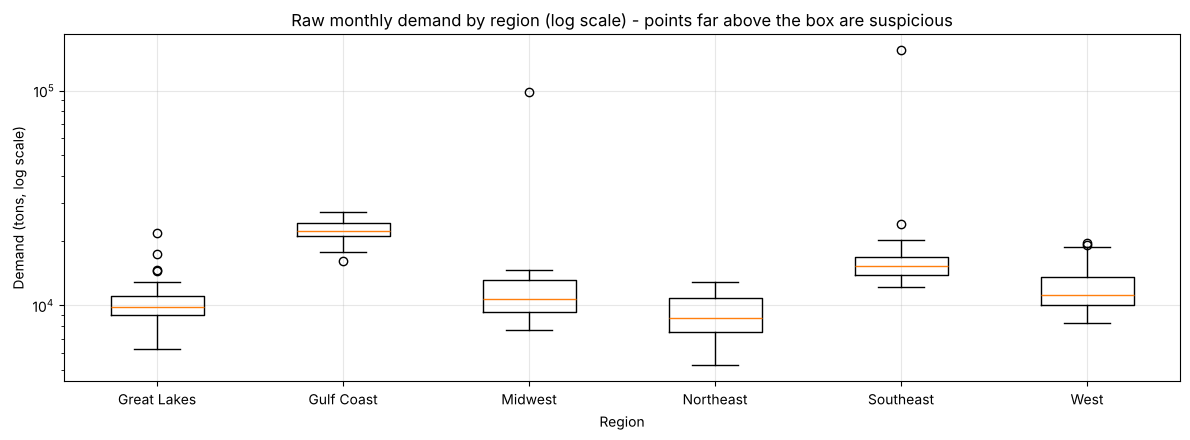

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))
regions_raw = sorted(check["region"].unique())
ax.boxplot([check.loc[check["region"] == r, "demand_tons"] for r in regions_raw])
ax.set_xticks(range(1, len(regions_raw) + 1))
ax.set_xticklabels(regions_raw)
ax.set_yscale("log")
ax.set_title("Raw monthly demand by region (log scale) - points far above the box are suspicious")
ax.set_xlabel("Region")
ax.set_ylabel("Demand (tons, log scale)")
plt.tight_layout()
plt.show()

In [9]:
check["times_region_median"] = check["demand_tons"] / check.groupby("region")["demand_tons"].transform("median")
check.sort_values("times_region_median", ascending=False).head(5)[
    ["date", "region", "demand_tons", "monthly_capacity_tons", "times_region_median"]]

,date,region,demand_tons,monthly_capacity_tons,times_region_median
62,2022-11-01,Southeast,"154,052.00","17,600.00",10.13
35,2022-03-01,Midwest,"98,418.00","13,300.00",9.17
212,2022-01-01,Great Lakes,"21,679.40","25,200.00",2.20
76,2021-12-01,Great Lakes,"17,361.50","25,200.00",1.77
96,2024-02-01,West,"19,440.60","15,900.00",1.73


**Problem found**
- Two values are about **10x their region's median**: Southeast Nov 2022 (154,052 t, 10.1x) and Midwest Mar 2022 (98,418 t, 9.2x). Both are far above plant capacity (17,600 and 13,300 t).
- The next values (2.2x, 1.8x) are the mislabelled Gulf Coast rows found in 3.3, not real outliers.
- Everything else is within about 2x of the median, which is normal month-to-month variation.

### 3.6 Demand above capacity - error or real?

In [10]:
above = check["demand_tons"] > check["monthly_capacity_tons"]
print(f"Months with demand above capacity: {above.sum()} of {len(check)} ({above.mean():.0%})")
print()
print("Share of months above capacity, by region:")
print((above.groupby(check["region"]).mean() * 100).round(0).to_string())

Months with demand above capacity: 48 of 291 (16%)

Share of months above capacity, by region:
region
Great Lakes   15.00
Gulf Coast    17.00
Midwest       17.00
Northeast     14.00
Southeast     19.00
West          17.00


**Not an error**
- About 16% of months show demand above capacity, spread evenly across **all** regions (14-19%).
- Real errors are usually rare and concentrated, not spread like this.
- These months cluster in recent years and in low-price or promotion months (see the capacity section later).

So we read `demand_tons` as **customer demand**, which can exceed what the plant can make. We keep these values.

### 3.7 Summary of problems found

| # | Problem | Rows | Plan |
|---|---|---|---|
| 1 | Region names spelled differently | 14 | Trim spaces, fix capitals |
| 2 | Row labelled Great Lakes but with another region's capacity | 5 | Move to the region its capacity matches |
| 3 | Exact duplicate rows | 3 | Remove |
| 4 | Demand about 10x too high | 2 | Divide by 10 (decimal point in the wrong place) |
| 5 | Competitor price missing | 6 | Interpolate within region |
| 6 | Promotion flag missing | 6 | Assume no promotion (0) |
| - | Demand above capacity | 48 | Keep: real demand, not an error |

## 4. Data cleaning

Each step fixes one problem from section 3. We work on a copy (`clean`) and never change the raw file.

### 4.1 Fix region names

**Why:** `"Gulf Coast "` (extra space) and `"great lakes"` (lowercase) are the same regions as
`"Gulf Coast"` and `"Great Lakes"`. Left as they are, every group-by would split one region into two.

In [11]:
clean = raw.copy()
names_fixed = (clean["region"] != clean["region"].str.strip().str.title()).sum()
clean["region"] = clean["region"].str.strip().str.title()

print("Rows with a name fixed:", names_fixed)
print(clean["region"].value_counts().to_string())

Rows with a name fixed: 14
region
Great Lakes    54
Northeast      49
Southeast      48
West           47
Midwest        47
Gulf Coast     46


### 4.2 Move rows that carry another region's capacity

**Why:** capacity never changes within a region, so it tells us which region a row really belongs to.
Five rows labelled Great Lakes carry the capacity of Gulf Coast, Midwest or West. Before moving a row we check
that its true region is missing that month - so the move fills a gap instead of creating a duplicate.

In [12]:
capacity_to_region = {11200: "Great Lakes", 11500: "Northeast", 13300: "Midwest",
                      15900: "West", 17600: "Southeast", 25200: "Gulf Coast"}
clean["region_by_capacity"] = clean["monthly_capacity_tons"].map(capacity_to_region)

wrong_region = clean[clean["region"] != clean["region_by_capacity"]]
wrong_region[["date", "region", "region_by_capacity", "price_usd_per_ton", "demand_tons", "monthly_capacity_tons"]]

,date,region,region_by_capacity,price_usd_per_ton,demand_tons,monthly_capacity_tons
34,2024-07-01,Great Lakes,Midwest,977.78,"14,541.80","13,300.00"
76,2021-12-01,Great Lakes,Gulf Coast,"1,044.94","17,361.50","25,200.00"
154,2024-02-01,Great Lakes,Midwest,"1,118.72","12,402.40","13,300.00"
212,2022-01-01,Great Lakes,Gulf Coast,"1,029.14","21,679.40","25,200.00"
284,2024-06-01,Great Lakes,West,947.30,"14,497.00","15,900.00"


In [13]:
for i, row in wrong_region.iterrows():
    already_there = ((clean["region"] == row["region_by_capacity"]) & (clean["date"] == row["date"])).any()
    print(f"{row['date'].date()}  {row['region']} -> {row['region_by_capacity']:11} "
          f"| does {row['region_by_capacity']} already have this month? {already_there}")

# all five targets are free, so move the rows
clean.loc[wrong_region.index, "region"] = clean.loc[wrong_region.index, "region_by_capacity"]
clean = clean.drop(columns="region_by_capacity")
rows_moved = len(wrong_region)

2024-07-01  Great Lakes -> Midwest     | does Midwest already have this month? False
2021-12-01  Great Lakes -> Gulf Coast  | does Gulf Coast already have this month? False
2024-02-01  Great Lakes -> Midwest     | does Midwest already have this month? False
2022-01-01  Great Lakes -> Gulf Coast  | does Gulf Coast already have this month? False
2024-06-01  Great Lakes -> West        | does West already have this month? False


### 4.3 Remove duplicate rows

**Why:** an exact copy of a row would count the same month twice and give it double weight in every average
and model.

In [14]:
rows_before = len(clean)
clean = clean.drop_duplicates()
duplicates_removed = rows_before - len(clean)

clean = clean.sort_values(["region", "date"]).reset_index(drop=True)

print("Duplicate rows removed:", duplicates_removed)
print("Any region-month still appearing twice?", clean.duplicated(["region", "date"]).any())
print("Rows now:", len(clean))

Duplicate rows removed: 3
Any region-month still appearing twice? False
Rows now: 288


### 4.4 Fix the two demand outliers

**Why:** two values are about 10x their region's normal level and 7-9x the plant capacity - physically
impossible. Nothing else in those rows (price, promotion, economy) is unusual. Dividing by 10 puts each value
right between its neighbouring months, which points to a decimal point in the wrong place. We correct them
rather than delete them, so the monthly series has no holes.

In [15]:
median_by_region = clean.groupby("region")["demand_tons"].transform("median")
outlier_rows = clean.index[clean["demand_tons"] > 3 * median_by_region]

for i in outlier_rows:
    before_month = clean.loc[i - 1, "demand_tons"]
    after_month = clean.loc[i + 1, "demand_tons"]
    value = clean.loc[i, "demand_tons"]
    print(f"{clean.loc[i, 'region']} {clean.loc[i, 'date'].date()}: {value:,.0f} t "
          f"| month before {before_month:,.0f} | month after {after_month:,.0f} | value / 10 = {value / 10:,.1f}")

clean.loc[outlier_rows, "demand_tons"] = (clean.loc[outlier_rows, "demand_tons"] / 10).round(1)
outliers_fixed = len(outlier_rows)

Midwest 2022-03-01: 98,418 t | month before 9,700 | month after 8,664 | value / 10 = 9,841.8
Southeast 2022-11-01: 154,052 t | month before 13,850 | month after 15,126 | value / 10 = 15,405.2


### 4.5 Fill missing values

**Why:**
- **Competitor price** moves smoothly from month to month, so the best guess for a missing month is the
  straight line between the months before and after it (linear interpolation, within the same region).
- **Promotion flag:** if no promotion was recorded, the safest assumption is that none ran (0).

For both we add a `_missing` flag column, so a model can still tell a filled value from a real one.

In [16]:
clean["competitor_price_missing"] = clean["competitor_price_usd_per_ton"].isna().astype(int)
clean["promo_missing"] = clean["promo_flag"].isna().astype(int)

clean["competitor_price_usd_per_ton"] = clean.groupby("region")["competitor_price_usd_per_ton"].transform(
    lambda s: s.interpolate(limit_direction="both"))
clean["promo_flag"] = clean["promo_flag"].fillna(0).astype(int)

# show the filled competitor prices
clean[clean["competitor_price_missing"] == 1][["date", "region", "competitor_price_usd_per_ton"]]

,date,region,competitor_price_usd_per_ton
43,2024-08-01,Great Lakes,"1,113.70"
44,2024-09-01,Great Lakes,"1,162.79"
112,2022-05-01,Midwest,"1,058.19"
148,2021-05-01,Northeast,"1,095.87"
169,2023-02-01,Northeast,"1,165.78"
287,2024-12-01,West,"1,167.24"


### 4.6 Demand above capacity - kept as it is

**Why:** it happens in every region, mostly in recent months and in low-price or promotion months. That is
the pattern of real customer demand that the plant could not fully serve, not a data error. We keep the
values and remember later that **tons sold = min(demand, capacity)**.

### 4.7 Final check and save

In [17]:
all_months = pd.date_range("2021-01-01", "2024-12-01", freq="MS")

print("Rows:", len(clean), "(expected 288)")
print("Months per region:", clean.groupby("region").size().unique())
print("Missing values left:", clean.isna().sum().sum())
print("Repeated region-months:", clean.duplicated(["region", "date"]).sum())
print("Capacity constant within each region:", (clean.groupby("region")["monthly_capacity_tons"].nunique() == 1).all())

clean.to_csv("data/panel_clean.csv", index=False)
print()
print("Saved data/panel_clean.csv")

Rows: 288 (expected 288)
Months per region: [48]
Missing values left: 0
Repeated region-months: 0
Capacity constant within each region: True

Saved data/panel_clean.csv


In [18]:
# summary of what was changed
changes = pd.DataFrame({
    "Problem": ["Region name spelled differently", "Row carried another region's capacity",
                "Exact duplicate row", "Demand ~10x too high (decimal point)",
                "Competitor price missing", "Promotion flag missing"],
    "Rows": [names_fixed, rows_moved, duplicates_removed, outliers_fixed,
             clean["competitor_price_missing"].sum(), clean["promo_missing"].sum()],
    "Fix": ["Tidied spelling", "Moved to the region its capacity matches", "Removed",
            "Divided by 10", "Interpolated within region", "Set to 0 (no promotion)"],
})
changes

,Problem,Rows,Fix
0,Region name spelled differently,14,Tidied spelling
1,Row carried another region's capacity,5,Moved to the region its capacity matches
2,Exact duplicate row,3,Removed
3,Demand ~10x too high (decimal point),2,Divided by 10
4,Competitor price missing,6,Interpolated within region
5,Promotion flag missing,6,Set to 0 (no promotion)


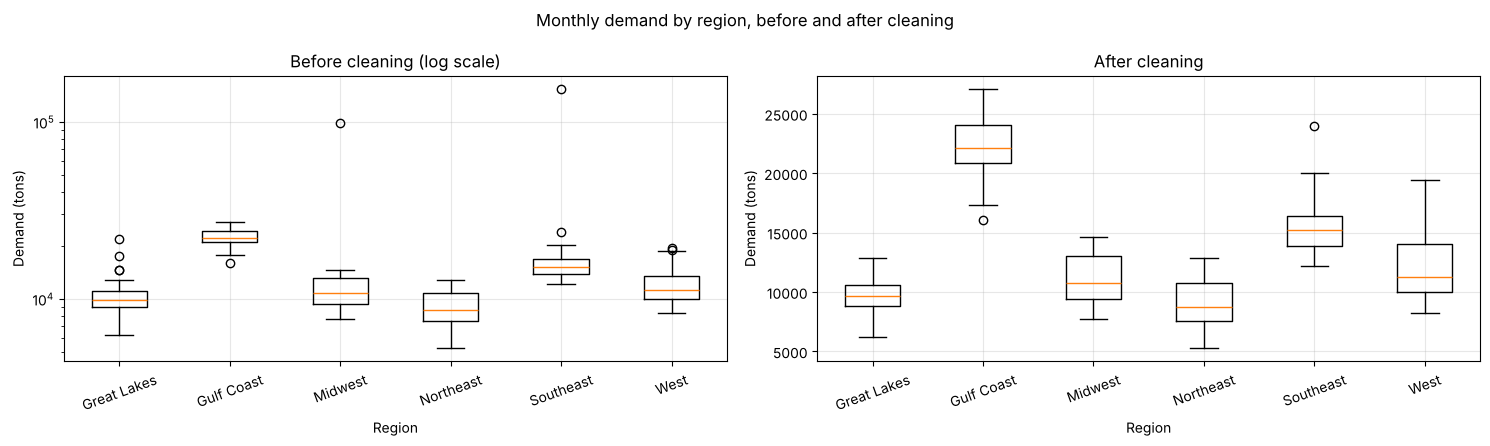

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
regions_clean = sorted(clean["region"].unique())

axes[0].boxplot([check.loc[check["region"] == r, "demand_tons"] for r in regions_raw])
axes[0].set_yscale("log")
axes[0].set_title("Before cleaning (log scale)")
axes[1].boxplot([clean.loc[clean["region"] == r, "demand_tons"] for r in regions_clean])
axes[1].set_title("After cleaning")

for ax, names in zip(axes, [regions_raw, regions_clean]):
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names, rotation=20)
    ax.set_xlabel("Region")
    ax.set_ylabel("Demand (tons)")

fig.suptitle("Monthly demand by region, before and after cleaning")
plt.tight_layout()
plt.show()

**Result**
- **288 rows:** all 6 regions x 48 months, with no gaps, no repeats and no missing values. Each region now has one capacity.
- **Before cleaning** (left chart): Midwest and Southeast each have one value near 100,000-150,000 t, and Great Lakes has extra high points (the mislabelled Gulf Coast / Midwest / West rows).
- **After cleaning** (right chart): those points are gone. Two real but unusual months remain:
  - Gulf Coast low (Nov 2021): we were much more expensive than the competitor.
  - Southeast high (Mar 2024): a promotion plus a very low price.
  They have clear business explanations, so we **keep** them.

The cleaned data is saved to `data/panel_clean.csv`.

## 5. EDA on the cleaned data

From here on we work with `clean`, keeping the original 8 columns.

In [20]:
cols = ["date", "region", "price_usd_per_ton", "competitor_price_usd_per_ton", "promo_flag",
        "industrial_index", "demand_tons", "monthly_capacity_tons"]
df = clean[cols].sort_values(["region", "date"]).reset_index(drop=True)

regions = sorted(df["region"].unique())
df.head()

,date,region,price_usd_per_ton,competitor_price_usd_per_ton,promo_flag,industrial_index,demand_tons,monthly_capacity_tons
0,2021-01-01,Great Lakes,"1,135.29",988.77,0,101.50,"8,574.70","11,200.00"
1,2021-02-01,Great Lakes,"1,078.00",977.51,1,100.60,"10,887.70","11,200.00"
2,2021-03-01,Great Lakes,"1,051.44",959.64,1,103.61,"12,323.20","11,200.00"
3,2021-04-01,Great Lakes,"1,085.29",950.89,0,100.89,"8,899.80","11,200.00"
4,2021-05-01,Great Lakes,"1,032.24",900.29,0,100.47,"11,171.10","11,200.00"


### 5.1 Data overview

In [21]:
print("Rows x columns :", df.shape)
print("Period         :", df["date"].min().date(), "to", df["date"].max().date())
print("Regions        :", regions)
print()
print("Months of data per region:")
print(df.groupby("region")["date"].count().to_string())

Rows x columns : (288, 8)
Period         : 2021-01-01 to 2024-12-01
Regions        : ['Great Lakes', 'Gulf Coast', 'Midwest', 'Northeast', 'Southeast', 'West']

Months of data per region:
region
Great Lakes    48
Gulf Coast     48
Midwest        48
Northeast      48
Southeast      48
West           48


In [22]:
# data types and missing values
print(df.dtypes)
print()
print("Missing values per column:")
print(df.isna().sum().to_string())

date                            datetime64[us]
region                                     str
price_usd_per_ton                      float64
competitor_price_usd_per_ton           float64
promo_flag                               int64
industrial_index                       float64
demand_tons                            float64
monthly_capacity_tons                  float64
dtype: object

Missing values per column:
date                            0
region                          0
price_usd_per_ton               0
competitor_price_usd_per_ton    0
promo_flag                      0
industrial_index                0
demand_tons                     0
monthly_capacity_tons           0


In [23]:
# summary statistics for the numeric columns
df.select_dtypes("number").describe().T

,count,mean,std,min,25%,50%,75%,max
price_usd_per_ton,288.00,"1,046.28",91.88,839.29,982.80,"1,031.64","1,116.31","1,287.30"
competitor_price_usd_per_ton,288.00,"1,049.90",90.87,820.86,986.74,"1,053.82","1,121.00","1,251.18"
promo_flag,288.00,0.20,0.40,0.00,0.00,0.00,0.00,1.00
industrial_index,288.00,104.90,3.03,98.07,102.21,104.69,107.38,110.89
demand_tons,288.00,"13,312.35","5,100.27","5,251.40","9,499.00","11,683.55","15,728.05","27,123.20"
monthly_capacity_tons,288.00,"15,783.33","4,795.61","11,200.00","11,500.00","14,600.00","17,600.00","25,200.00"


**What we see**
- 288 rows = 6 regions x 48 months, with no missing months and no missing values (after the cleaning in section 4).
- Monthly demand ranges from about 5,300 to 27,100 tons (average 13,300).
- Our average price ($1,046/t) is almost the same as the competitor's ($1,050/t), but both move between roughly $820 and $1,290.
- A promotion ran in 20% of months. The industrial index moves in a narrow band (98-111).

**So what:** the data is complete and clean enough to analyse. The wide range in demand already hints that regions are very different in size.

## 6. Region summary

One line per region. `cv_demand` is the **coefficient of variation** (std / mean): how much demand swings
month to month relative to its size. `utilisation` = demand / capacity.

In [24]:
df["utilisation"] = df["demand_tons"] / df["monthly_capacity_tons"]

region_summary = df.groupby("region").agg(
    avg_demand_t=("demand_tons", "mean"),
    std_demand_t=("demand_tons", "std"),
    avg_price_usd=("price_usd_per_ton", "mean"),
    avg_competitor_usd=("competitor_price_usd_per_ton", "mean"),
    capacity_t=("monthly_capacity_tons", "first"),
    avg_utilisation=("utilisation", "mean"),
    promo_share=("promo_flag", "mean"),
)
region_summary["cv_demand"] = region_summary["std_demand_t"] / region_summary["avg_demand_t"]
region_summary.sort_values("avg_demand_t", ascending=False)

,avg_demand_t,std_demand_t,avg_price_usd,avg_competitor_usd,capacity_t,avg_utilisation,promo_share,cv_demand
region,,,,,,,,
Gulf Coast,"22,375.95","2,522.47",977.92,949.15,"25,200.00",0.89,0.17,0.11
Southeast,"15,504.68","2,302.06",995.52,"1,066.74","17,600.00",0.88,0.19,0.15
West,"12,286.51","2,987.85",984.66,"1,145.98","15,900.00",0.77,0.23,0.24
Midwest,"11,055.75","2,089.50","1,122.93","1,054.59","13,300.00",0.83,0.25,0.19
Great Lakes,"9,658.00","1,452.51","1,115.13",982.22,"11,200.00",0.86,0.19,0.15
Northeast,"8,993.21","2,001.92","1,081.56","1,100.71","11,500.00",0.78,0.21,0.22


**What we see**
- **Size:** Gulf Coast is by far the biggest market (about 22,400 t a month), 2.5x Northeast (about 9,000 t).
- **Price position:** we are much cheaper than the competitor in West ($985 vs $1,146, about 14% below) and much more expensive in Great Lakes ($1,115 vs $982, about 14% above).
- **Volatility:** West swings the most (coefficient of variation 0.24) and Gulf Coast the least (0.11).
- **Capacity:** on average, plants run at 77-89% of capacity.

**So what:** each region has its own size, price level and volatility, so one average for all regions would describe none of them well.

## 7. Region-wise or overall?

Left: total demand of all regions added together. Right: the spread of monthly demand in each region (box plot).

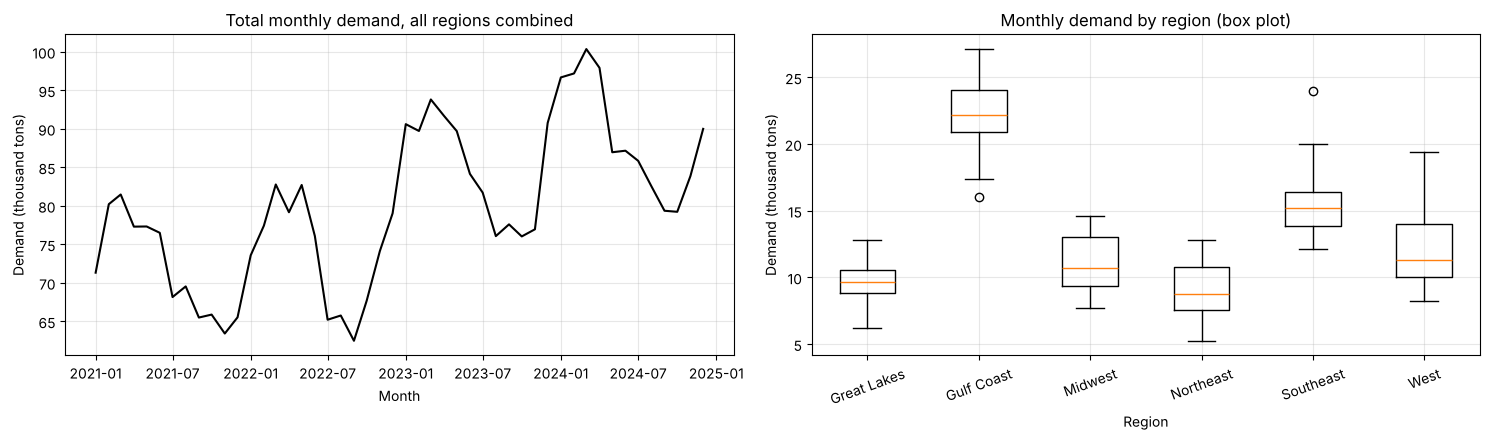

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# total demand across all regions
total = df.groupby("date")["demand_tons"].sum()
axes[0].plot(total.index, total / 1000, color="black")
axes[0].set_title("Total monthly demand, all regions combined")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Demand (thousand tons)")

# distribution of demand per region
demand_by_region = [df.loc[df["region"] == r, "demand_tons"] / 1000 for r in regions]
axes[1].boxplot(demand_by_region)
axes[1].set_xticks(range(1, len(regions) + 1))
axes[1].set_xticklabels(regions, rotation=20)
axes[1].set_title("Monthly demand by region (box plot)")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Demand (thousand tons)")

plt.tight_layout()
plt.show()

**What we see**
- The **total** line (left) shows growth plus a yearly wave: high in early spring, low in late summer/autumn.
- The **box plot** (right) shows that regions live on completely different scales. Gulf Coast's typical month (about 22,000 t) is larger than any month Northeast or Great Lakes ever had.

**Decision: analyse region by region.** Adding regions together hides that they grow at different speeds and that prices differ by region. Every chart from here on is region-wise, and the models later include a separate level for each region (region fixed effects).

## 8. Trend

Monthly demand per region, with a **12-month rolling average** (removes seasonality, shows the trend)
and the plant capacity line.

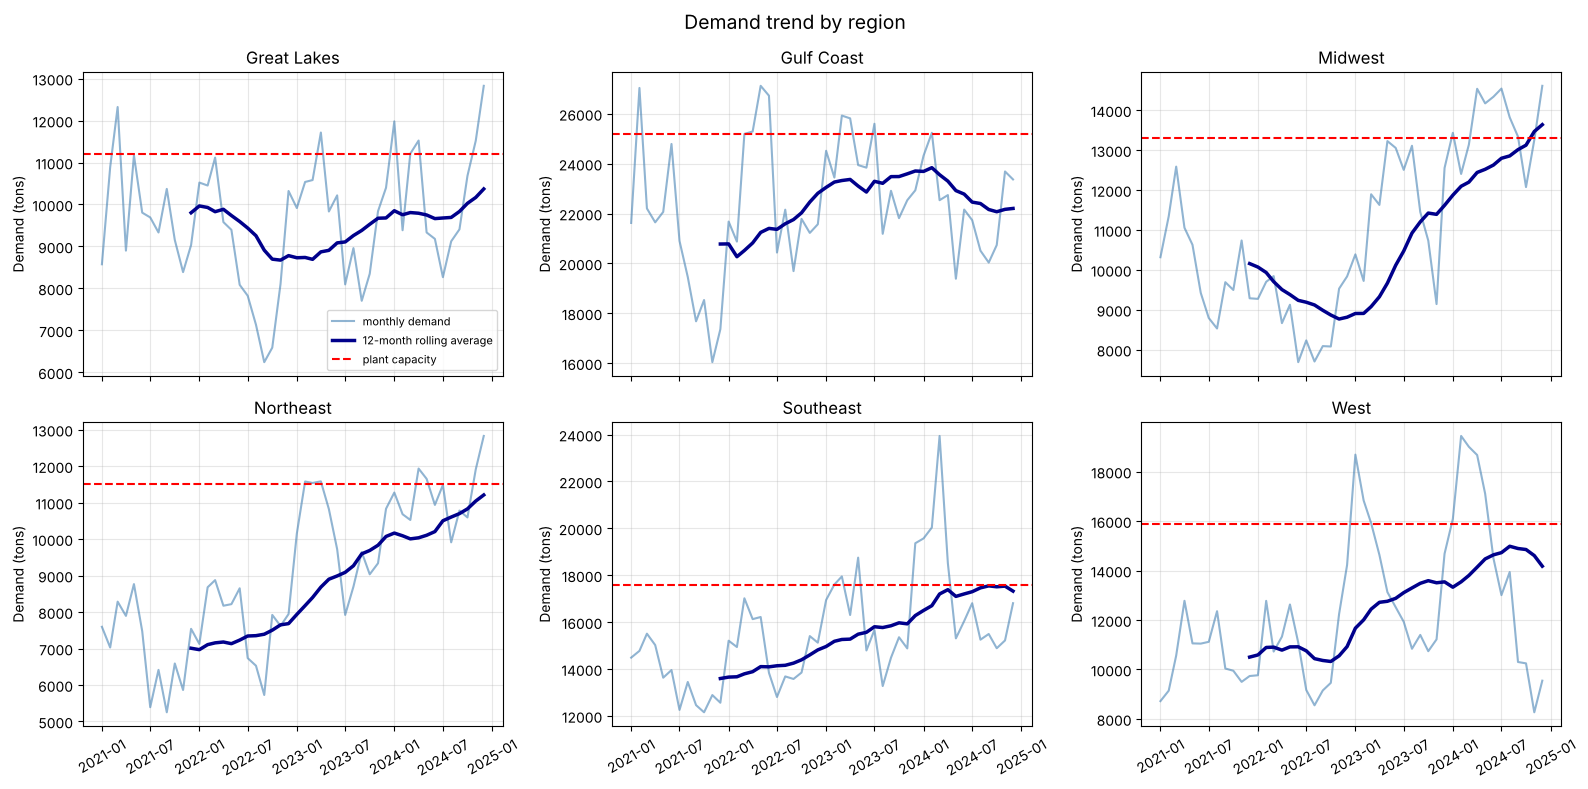

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)

for ax, region in zip(axes.flat, regions):
    d = df[df["region"] == region]
    rolling_12m = d["demand_tons"].rolling(12).mean()

    ax.plot(d["date"], d["demand_tons"], color="steelblue", alpha=0.6, label="monthly demand")
    ax.plot(d["date"], rolling_12m, color="darkblue", linewidth=2.5, label="12-month rolling average")
    ax.axhline(d["monthly_capacity_tons"].iloc[0], color="red", linestyle="--", label="plant capacity")

    ax.set_title(region)
    ax.set_ylabel("Demand (tons)")
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(fontsize=8)
fig.suptitle("Demand trend by region", fontsize=14)
plt.tight_layout()
plt.show()

In [27]:
# average monthly demand per year, and growth from 2021 to 2024
df["year"] = df["date"].dt.year
yearly = df.pivot_table(index="region", columns="year", values="demand_tons", aggfunc="mean")
yearly["growth_2021_to_2024_%"] = ((yearly[2024] / yearly[2021] - 1) * 100).round(1)
yearly.round(1)

year,2021,2022,2023,2024,growth_2021_to_2024_%
region,,,,,
Great Lakes,"9,802.60","8,780.60","9,678.60","10,370.10",5.80
Gulf Coast,"20,778.60","22,813.00","23,706.80","22,205.40",6.90
Midwest,"10,156.20","8,812.50","11,616.60","13,637.70",34.30
Northeast,"7,008.00","7,683.00","10,072.10","11,209.70",60.00
Southeast,"13,596.40","14,817.20","16,281.30","17,323.80",27.40
West,"10,500.70","10,926.40","13,542.80","14,176.20",35.00


**What we see**
- Demand grew in every region from 2021 to 2024, but at very different speeds:
  - Northeast +60%
  - West +35%
  - Midwest +34%
  - Southeast +27%
  - Gulf Coast +7%
  - Great Lakes +6%
- Midwest dipped in 2022 before rising strongly. Gulf Coast peaked in 2023 and then eased.
- By 2024 the 12-month average is at or near the red capacity line in Midwest, Northeast and Southeast. Individual months cross it in every region.

**So what:** there is a clear upward trend, but it is region-specific. The next question is *why* demand grew. The price chart below gives part of the answer.

### 8b. Price trend

Our price (solid) and the competitor's price (dashed) over time. Prices often explain part of a demand trend.

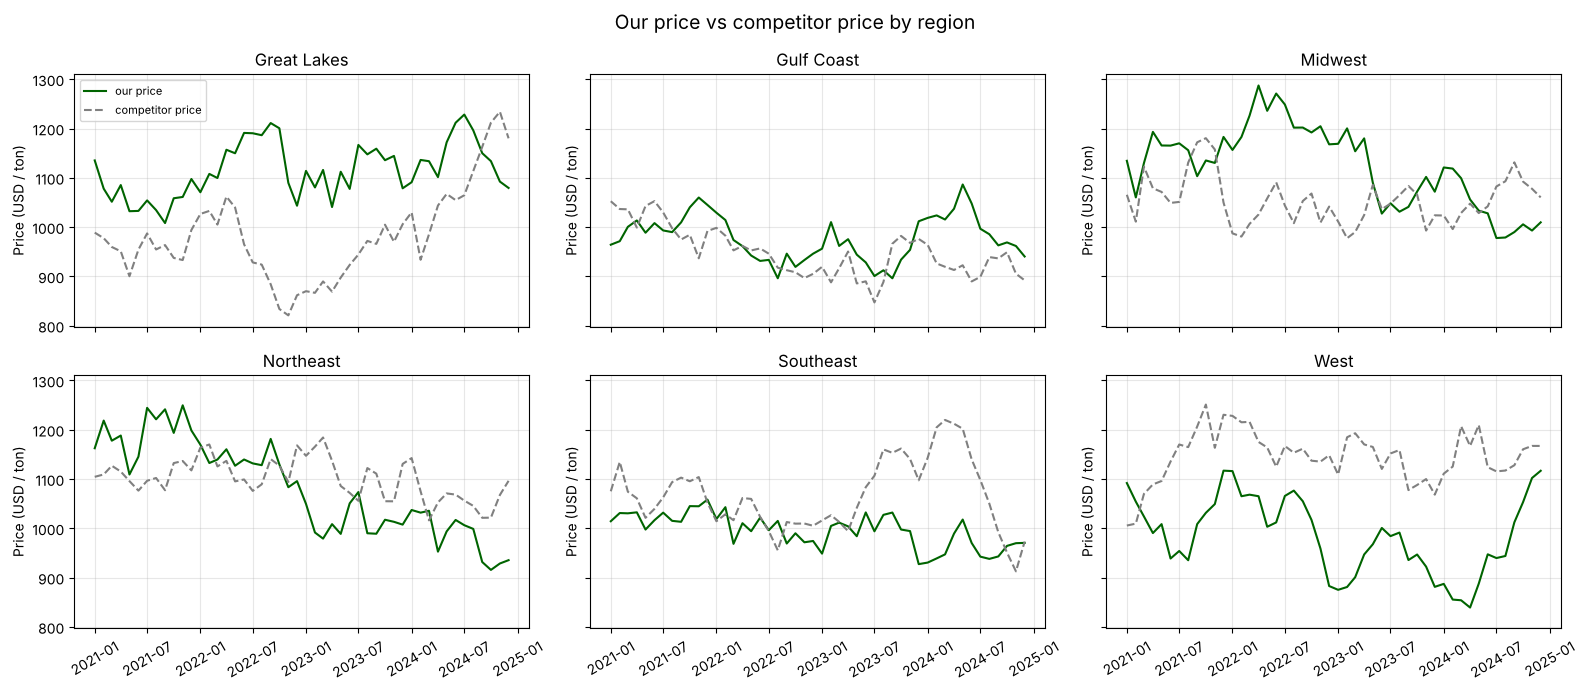

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True, sharey=True)

for ax, region in zip(axes.flat, regions):
    d = df[df["region"] == region]
    ax.plot(d["date"], d["price_usd_per_ton"], color="darkgreen", label="our price")
    ax.plot(d["date"], d["competitor_price_usd_per_ton"], color="grey", linestyle="--", label="competitor price")
    ax.set_title(region)
    ax.set_ylabel("Price (USD / ton)")
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(fontsize=8)
fig.suptitle("Our price vs competitor price by region", fontsize=14)
plt.tight_layout()
plt.show()

In [29]:
yearly_price = df.pivot_table(index="region", columns="year", values="price_usd_per_ton", aggfunc="mean")
yearly_price["change_2021_to_2024_%"] = ((yearly_price[2024] / yearly_price[2021] - 1) * 100).round(1)
yearly_price.round(1)

year,2021,2022,2023,2024,change_2021_to_2024_%
region,,,,,
Great Lakes,"1,060.80","1,141.50","1,114.40","1,143.90",7.80
Gulf Coast,"1,007.00",952.20,948.70,"1,003.80",-0.30
Midwest,"1,143.80","1,214.80","1,098.90","1,034.20",-9.60
Northeast,"1,195.90","1,135.00","1,013.30",982.10,-17.90
Southeast,"1,027.60",997.80,996.50,960.20,-6.60
West,"1,017.00","1,032.20",936.20,953.30,-6.30


**What we see**
- The regions where we **cut prices** grew fastest:
  - Northeast: price -18%, demand +60%
  - Midwest: price -10%, demand +34%
  - Southeast: price -7%, demand +27%
- Where prices **rose or stayed flat**, demand barely grew:
  - Great Lakes: price +8%, demand +6%
  - Gulf Coast: price flat, demand +7%
- In West we priced below the competitor almost the whole time, and very low (about $840-880/t) in early 2023 and early 2024. Those are exactly West's demand spikes in the trend chart.

**So what:** a large part of the demand trend looks price-driven. But the economy was also growing at the same time, so the model must separate the two effects rather than credit everything to price.

## 9. Seasonality

Demand is growing, so a plain "average by month" would mix trend and season. Instead we use the classical
**ratio-to-moving-average** method:

seasonal index = demand / 12-month centred moving average

An index of 1.10 means that month is typically 10% above the underlying trend.

In [30]:
df["trend_12m"] = df.groupby("region")["demand_tons"].transform(lambda s: s.rolling(12, center=True).mean())
df["seasonal_ratio"] = df["demand_tons"] / df["trend_12m"]
df["month"] = df["date"].dt.month

seasonal_index = df.pivot_table(index="month", columns="region", values="seasonal_ratio", aggfunc="mean")
seasonal_index["all regions"] = seasonal_index.mean(axis=1)
seasonal_index.round(3)

region,Great Lakes,Gulf Coast,Midwest,Northeast,Southeast,West,all regions
month,,,,,,,
1,1.14,1.05,1.03,1.07,1.10,1.15,1.09
2,1.08,1.04,0.98,1.16,1.11,1.26,1.10
3,1.17,1.10,1.06,1.15,1.24,1.16,1.15
4,1.17,1.10,1.04,1.14,1.07,1.14,1.11
5,1.01,1.04,1.09,1.10,1.06,1.11,1.07
6,0.96,1.07,1.03,1.04,0.93,0.99,1.00
7,0.88,0.99,0.99,0.86,0.93,0.92,0.93
8,0.89,0.93,0.94,0.87,0.90,0.90,0.91
9,0.85,0.89,0.94,0.80,0.89,0.84,0.87


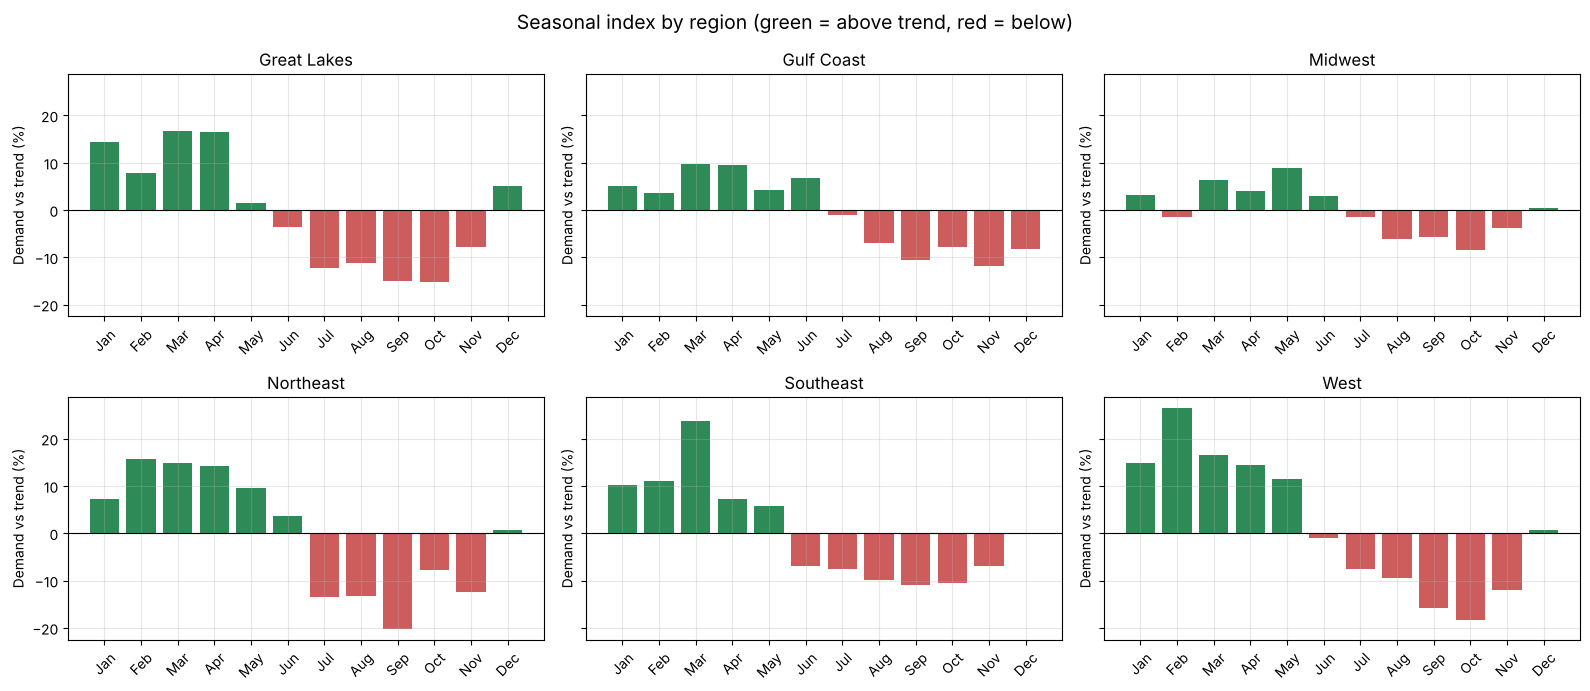

In [31]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey=True)

for ax, region in zip(axes.flat, regions):
    values = (seasonal_index[region] - 1) * 100            # % above / below trend
    colors = ["seagreen" if v > 0 else "indianred" for v in values]
    ax.bar(month_names, values, color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(region)
    ax.set_ylabel("Demand vs trend (%)")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Seasonal index by region (green = above trend, red = below)", fontsize=14)
plt.tight_layout()
plt.show()

**What we see**
- All regions share the **same seasonal shape**: demand is above trend from January to May (on average about +7% to +15%, peaking in March) and below trend from July to November (lowest in September, about -13%).
- The **strength** differs. West has the strongest pattern (February +26%, October -18%); Northeast and Great Lakes are also strong. Midwest is the weakest (within about +/-9%).

**So what:** seasonality is real and must be in the forecast (month-of-year effects). Because the shape is common to all regions, one shared set of month effects is a reasonable, simple choice.

*Caveat:* these indexes are based on raw demand, so a few months may also include price or promotion effects (for example Southeast in March 2024, which had a promotion and a very low price). The models control for that.

### 9b. Seasonal decomposition (one region as an example)

`seasonal_decompose` splits the series into **trend + seasonal + residual** (multiplicative, period = 12 months).
Shown for Midwest; the other regions look similar.

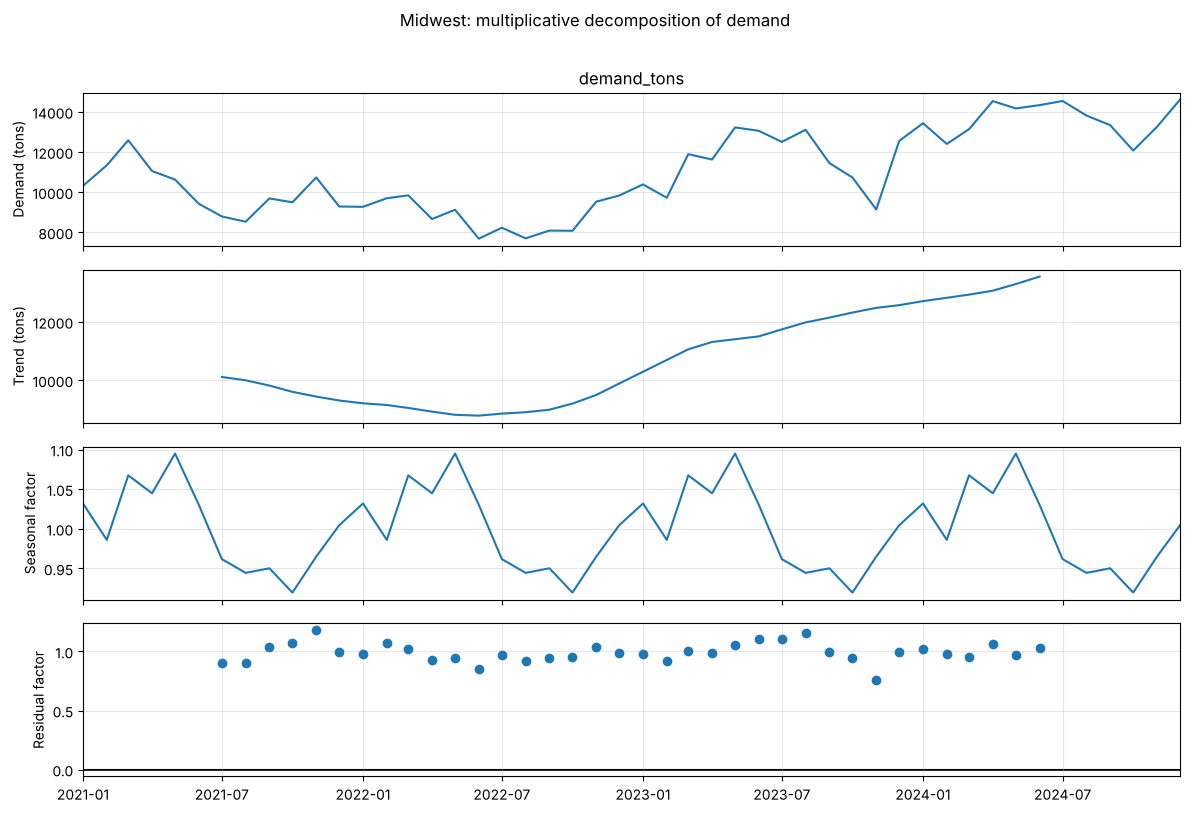

In [32]:
midwest = df[df["region"] == "Midwest"].set_index("date")["demand_tons"]
decomposition = seasonal_decompose(midwest, model="multiplicative", period=12)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
fig.axes[0].set_ylabel("Demand (tons)")
fig.axes[1].set_ylabel("Trend (tons)")
fig.axes[2].set_ylabel("Seasonal factor")
fig.axes[3].set_ylabel("Residual factor")
fig.suptitle("Midwest: multiplicative decomposition of demand", y=1.01)
plt.tight_layout()
plt.show()

**What we see (Midwest)**
- **Trend:** falls to about 8,800 t in mid-2022, then rises steadily to about 13,600 t by mid-2024.
- **Seasonal factor:** repeats every year between about 0.92 and 1.10, i.e. roughly +/-9% around the trend.
- **Residual:** mostly between 0.9 and 1.1, so trend and season explain most of the movement. The biggest leftover is a dip at the end of 2023 (about 0.76), which trend and season cannot explain. That is where price and other drivers come in.

### 9c. Autocorrelation (ACF)

How strongly this month's demand is related to demand 1, 2, ... 24 months earlier.
Bars outside the blue band are statistically significant.

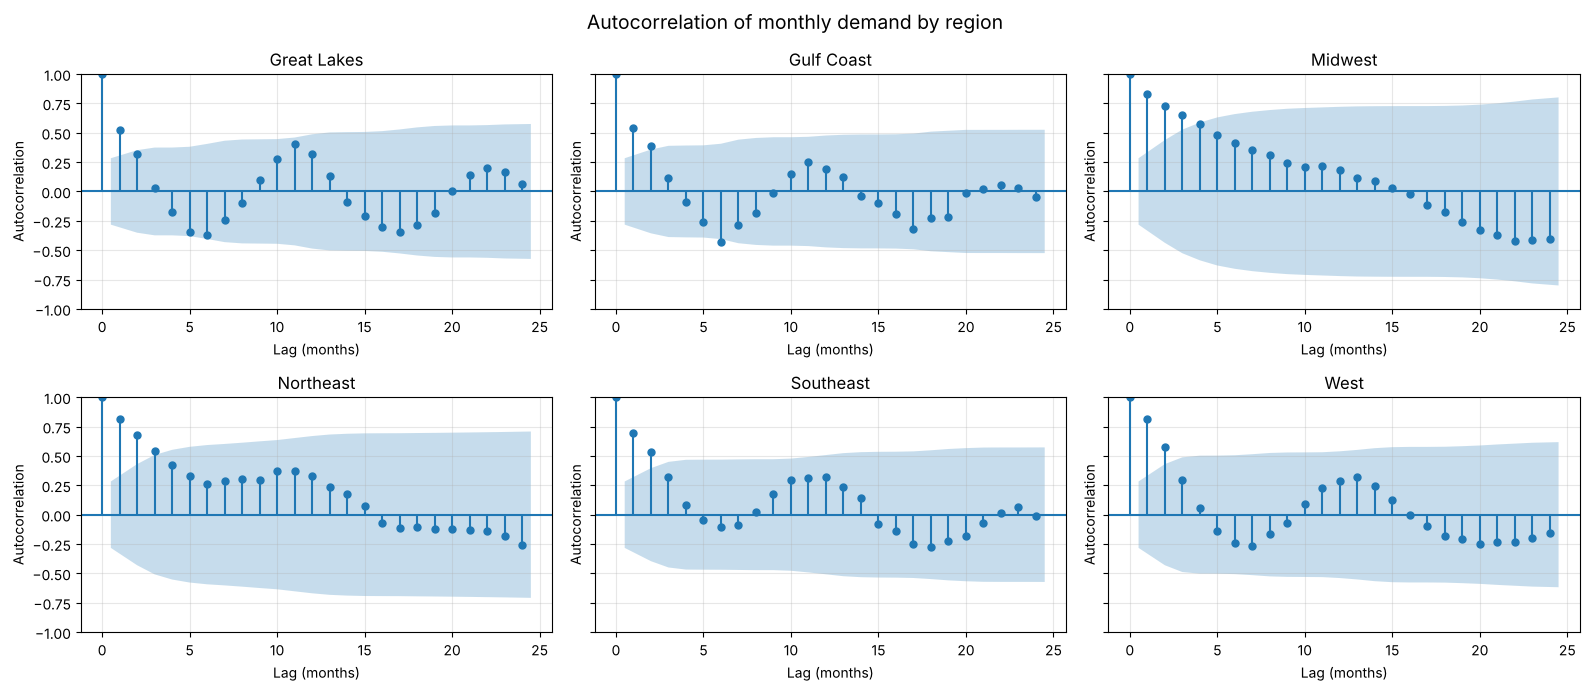

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey=True)

for ax, region in zip(axes.flat, regions):
    series = df.loc[df["region"] == region, "demand_tons"]
    plot_acf(series, lags=24, ax=ax, title=region)
    ax.set_xlabel("Lag (months)")
    ax.set_ylabel("Autocorrelation")

fig.suptitle("Autocorrelation of monthly demand by region", fontsize=14)
plt.tight_layout()
plt.show()

**What we see**
- **Lag 1 is strongly positive in every region (about 0.5-0.8):** if demand was high last month, it is usually high this month.
- **Midwest and Northeast:** autocorrelation fades slowly over many lags, the typical signature of a **trend**.
- **Great Lakes, Gulf Coast, Southeast and West:** a wave that turns negative around lag 6 and positive again around lags 11-12, the signature of **12-month seasonality**. With only 48 months per region, few of these bars cross the significance band.

**So what:**
- The "same as last month" forecast will be a fair baseline to beat.
- Trend and seasonality need to be handled explicitly.
- If the model's leftover errors still show autocorrelation, that would point to a time-series model (ARIMA-type errors). We check this later.

## 10. Price vs demand

Each dot is one month. The red curve is fitted on **log price vs log demand**, so its slope is the
**price elasticity**: the % change in demand for a 1% change in price (e.g. -2 means +1% price -> about -2% demand).

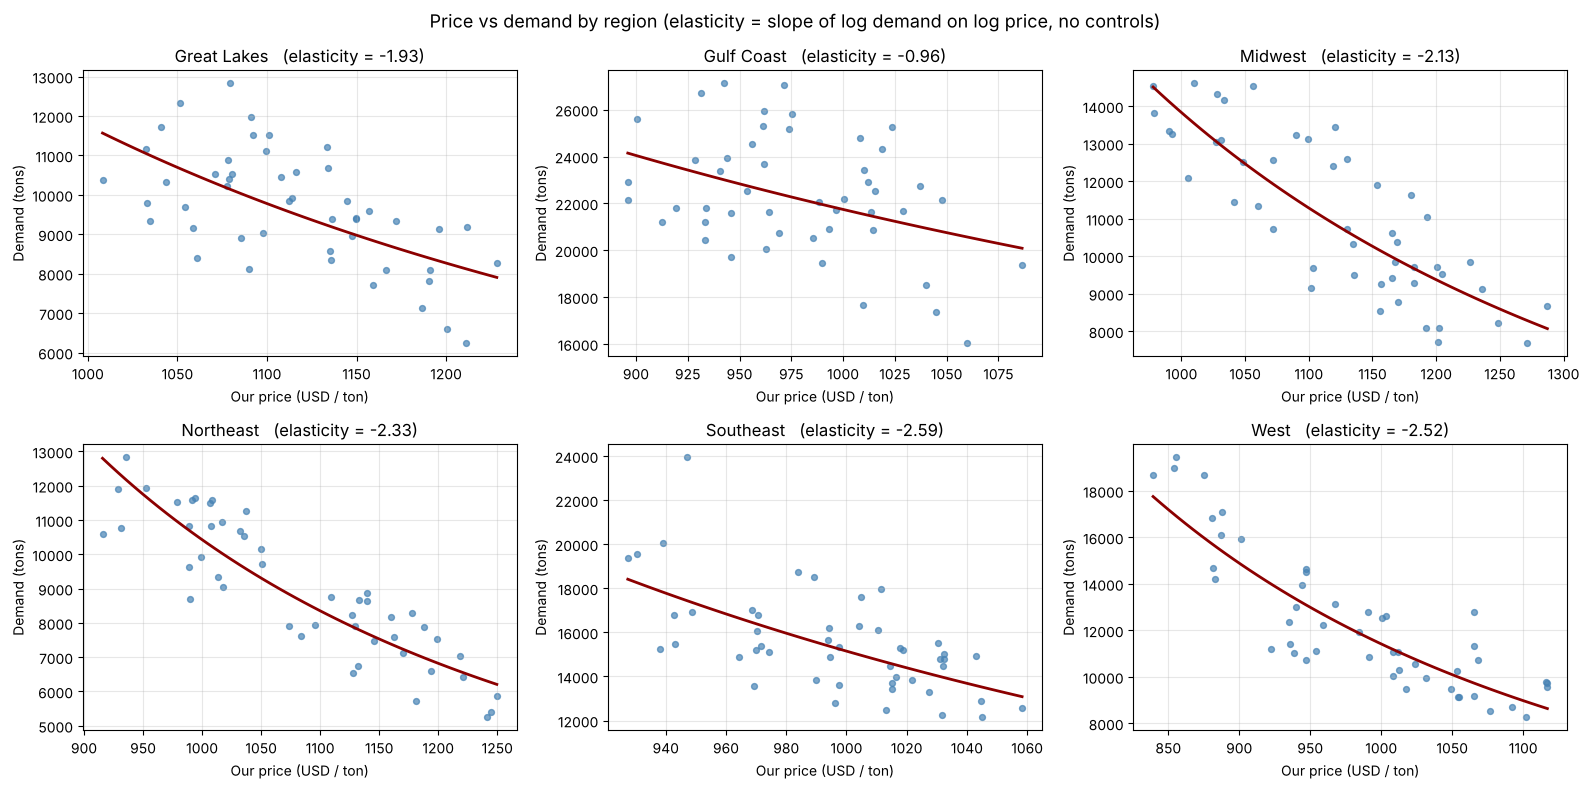

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
slopes = {}

for ax, region in zip(axes.flat, regions):
    d = df[df["region"] == region]
    slope, intercept = np.polyfit(np.log(d["price_usd_per_ton"]), np.log(d["demand_tons"]), 1)
    slopes[region] = slope

    # fitted curve: demand = a * price ^ slope  (a straight line in log-log terms)
    x = np.linspace(d["price_usd_per_ton"].min(), d["price_usd_per_ton"].max(), 50)
    ax.scatter(d["price_usd_per_ton"], d["demand_tons"], s=18, color="steelblue", alpha=0.7)
    ax.plot(x, np.exp(intercept) * x ** slope, color="darkred", linewidth=2)

    ax.set_title(f"{region}   (elasticity = {slope:.2f})")
    ax.set_xlabel("Our price (USD / ton)")
    ax.set_ylabel("Demand (tons)")

fig.suptitle("Price vs demand by region (elasticity = slope of log demand on log price, no controls)", fontsize=13)
plt.tight_layout()
plt.show()

In [35]:
# what if we ignored regions and fitted one line through all the data?
pooled_slope, _ = np.polyfit(np.log(df["price_usd_per_ton"]), np.log(df["demand_tons"]), 1)

print(f"Slope with all regions pooled together : {pooled_slope:.2f}")
print(f"Average slope within each region       : {np.mean(list(slopes.values())):.2f}")
print()
print("How much did our price move in each region? (min / max / variation %)")
price_range = df.groupby("region")["price_usd_per_ton"].agg(["min", "max", "std", "mean"])
price_range["variation_%"] = price_range["std"] / price_range["mean"] * 100
print(price_range[["min", "max", "variation_%"]].round(1).to_string())

Slope with all regions pooled together : -3.04
Average slope within each region       : -2.08

How much did our price move in each region? (min / max / variation %)
                 min      max  variation_%
region                                    
Great Lakes 1,008.20 1,228.30         5.00
Gulf Coast    896.10 1,086.40         4.60
Midwest       977.80 1,287.30         7.30
Northeast     915.70 1,249.60         8.80
Southeast     927.40 1,058.30         3.40
West          839.30 1,117.00         7.90


**What we see**
- In **every region**, higher price goes with lower demand. Raw elasticities run from -0.96 (Gulf Coast) to -2.59 (Southeast); most are around -2.
- If we fit one line through all regions together, the slope is -3.04, but the average within regions is -2.08. Pooling **exaggerates** price sensitivity, because the cheap regions (Gulf Coast, Southeast, West) also happen to be the big ones. This is another reason to compare each region with itself.
- Our price moved least in Southeast (+/-3.4%) and Gulf Coast (+/-4.6%), so their slopes are the least reliable.

**So what:** demand is clearly price-sensitive, roughly -2 (1% higher price -> about 2% less demand). These are raw slopes with no controls. Because prices fell while the economy grew, they probably overstate the true effect. Step 3 estimates it properly.

## 11. Promotions

Average demand in months with and without a promotion, per region. To remove trend and season we compare
**demand vs its 12-month trend** (the `seasonal_ratio` from section 9), not raw tons.

In [36]:
promo = df.dropna(subset=["seasonal_ratio"]).groupby(["region", "promo_flag"])["seasonal_ratio"].mean().unstack()
promo["uplift_%"] = (promo[1] / promo[0] - 1) * 100

# do promotions come with price cuts? compare price in promo vs non-promo months, per region
price_in_promo = df.groupby(["region", "promo_flag"])["price_usd_per_ton"].mean().unstack()
promo["price_diff_in_promo_%"] = (price_in_promo[1] / price_in_promo[0] - 1) * 100
promo["promo_months"] = df.groupby("region")["promo_flag"].sum()
promo[["promo_months", "uplift_%", "price_diff_in_promo_%"]].round(1)

promo_flag,promo_months,uplift_%,price_diff_in_promo_%
region,,,
Great Lakes,9,7.60,-0.30
Gulf Coast,8,4.70,2.20
Midwest,12,6.80,-0.20
Northeast,10,2.60,0.20
Southeast,9,7.20,1.00
West,11,-1.00,0.20


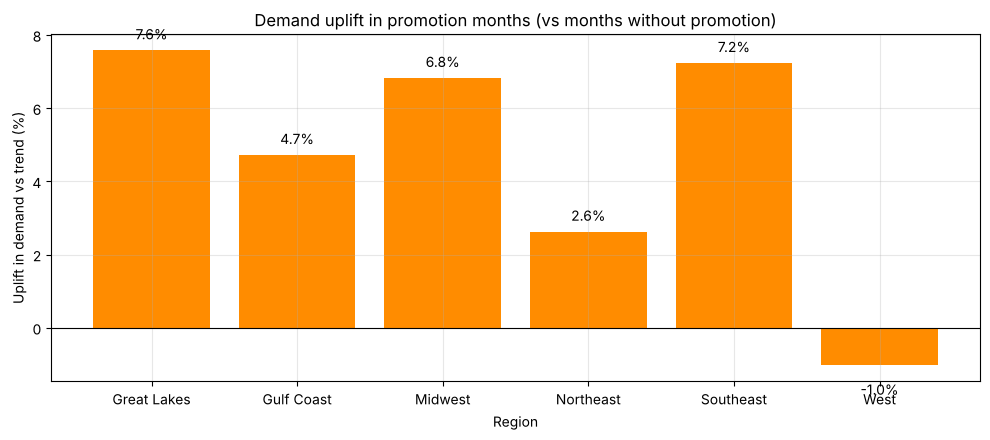

In [37]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(promo.index, promo["uplift_%"], color="darkorange")
for i, value in enumerate(promo["uplift_%"]):
    ax.text(i, value + (0.3 if value >= 0 else -0.8), f"{value:.1f}%", ha="center")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Demand uplift in promotion months (vs months without promotion)")
ax.set_xlabel("Region")
ax.set_ylabel("Uplift in demand vs trend (%)")
plt.tight_layout()
plt.show()

**What we see**
- Compared with the underlying trend, promotion months are about **3% to 8% higher** in five regions (Great Lakes +7.6%, Southeast +7.2%, Midwest +6.8%). West shows -1%.
- Promotions are **not price cuts**: in promo months our price is within about 2% of normal.
- Each region has only 8-12 promotion months, so these numbers are noisy. West's -1% is most likely noise rather than a real negative effect.

**So what:** promotions give a modest lift and work separately from price. Keep `promo_flag` as a driver in the models.

## 12. Competitor price and the economy

To compare regions of different size on one chart, demand is shown as **% above or below that region's own
average**. Colours = regions.

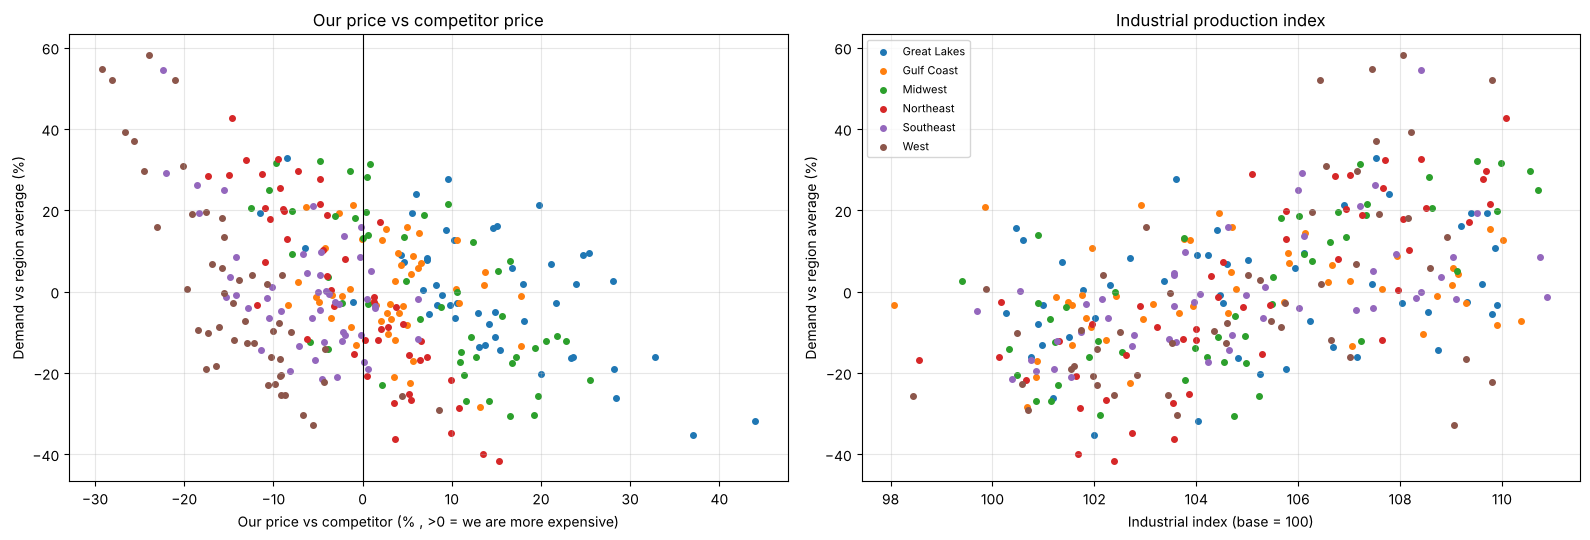

In [38]:
df["demand_vs_region_avg_%"] = (df["demand_tons"] / df.groupby("region")["demand_tons"].transform("mean") - 1) * 100
df["price_gap_vs_competitor_%"] = (df["price_usd_per_ton"] / df["competitor_price_usd_per_ton"] - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

for region in regions:
    d = df[df["region"] == region]
    axes[0].scatter(d["price_gap_vs_competitor_%"], d["demand_vs_region_avg_%"], s=16, label=region)
    axes[1].scatter(d["industrial_index"], d["demand_vs_region_avg_%"], s=16, label=region)

axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Our price vs competitor price")
axes[0].set_xlabel("Our price vs competitor (% , >0 = we are more expensive)")
axes[0].set_ylabel("Demand vs region average (%)")

axes[1].set_title("Industrial production index")
axes[1].set_xlabel("Industrial index (base = 100)")
axes[1].set_ylabel("Demand vs region average (%)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [39]:
# correlation of demand with each driver, calculated inside each region
drivers = ["price_usd_per_ton", "competitor_price_usd_per_ton", "promo_flag", "industrial_index"]
correlations = pd.DataFrame({
    region: df[df["region"] == region][drivers].corrwith(df.loc[df["region"] == region, "demand_tons"])
    for region in regions
}).T
correlations.columns = ["our price", "competitor price", "promotion", "industrial index"]
correlations.round(2)

,our price,competitor price,promotion,industrial index
Great Lakes,-0.61,0.33,0.44,0.24
Gulf Coast,-0.37,-0.10,0.25,0.24
Midwest,-0.82,0.06,0.21,0.70
Northeast,-0.89,-0.20,0.06,0.78
Southeast,-0.63,0.32,0.27,0.56
West,-0.86,0.07,0.09,0.53


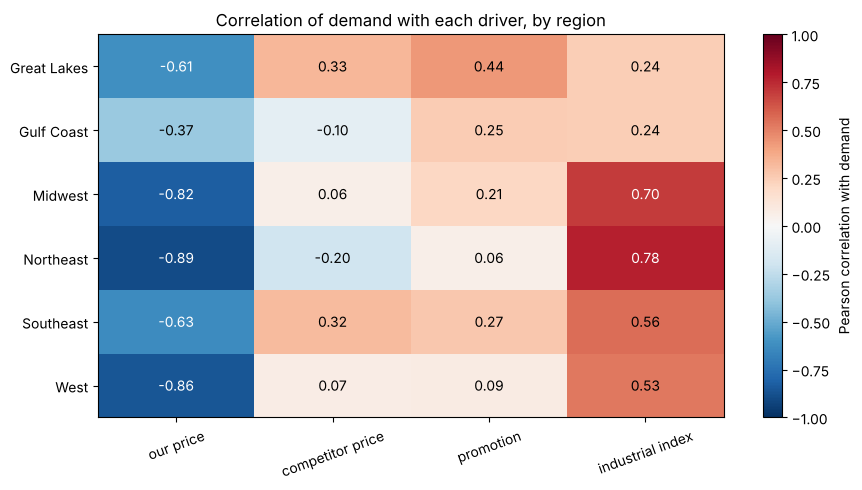

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=20)
ax.set_yticks(range(len(regions)))
ax.set_yticklabels(regions)
for i in range(len(regions)):
    for j in range(len(correlations.columns)):
        value = correlations.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.6 else "black")
fig.colorbar(image, label="Pearson correlation with demand")
ax.set_title("Correlation of demand with each driver, by region")
plt.tight_layout()
plt.show()

In [41]:
# drivers can also move together, which makes their effects hard to separate
print("Correlation between our price and the industrial index, per region:")
print(df.groupby("region").apply(lambda d: d["price_usd_per_ton"].corr(d["industrial_index"])).round(2).to_string())

Correlation between our price and the industrial index, per region:
region
Great Lakes    0.43
Gulf Coast     0.03
Midwest       -0.53
Northeast     -0.80
Southeast     -0.63
West          -0.37


**What we see**
- **Our price** has the strongest link with demand in every region (correlation -0.37 to -0.89).
- **The economy** (industrial index) is clearly positive (+0.24 to +0.78), strongest in Midwest and Northeast.
- **Competitor price** is weak and mixed (-0.20 to +0.33). In the left scatter, demand is higher when we are cheaper than the competitor. These points are mostly West, where we were often 10-30% cheaper. Great Lakes is the only region often 20-40% more expensive.
- **Warning:** in Northeast (-0.80), Southeast (-0.63) and Midwest (-0.53), our price and the industrial index moved in opposite directions: we cut prices while the economy grew. **Simple correlations therefore overstate both effects.** A model that includes price and the economy together is needed to separate them.

**So what:** price, the economy and promotions are the main drivers; competitor price is secondary. Price and the economy must be modelled together.

## 13. Plant capacity

**Utilisation** = demand / capacity. Above 100% means customers wanted more than the plant could make.

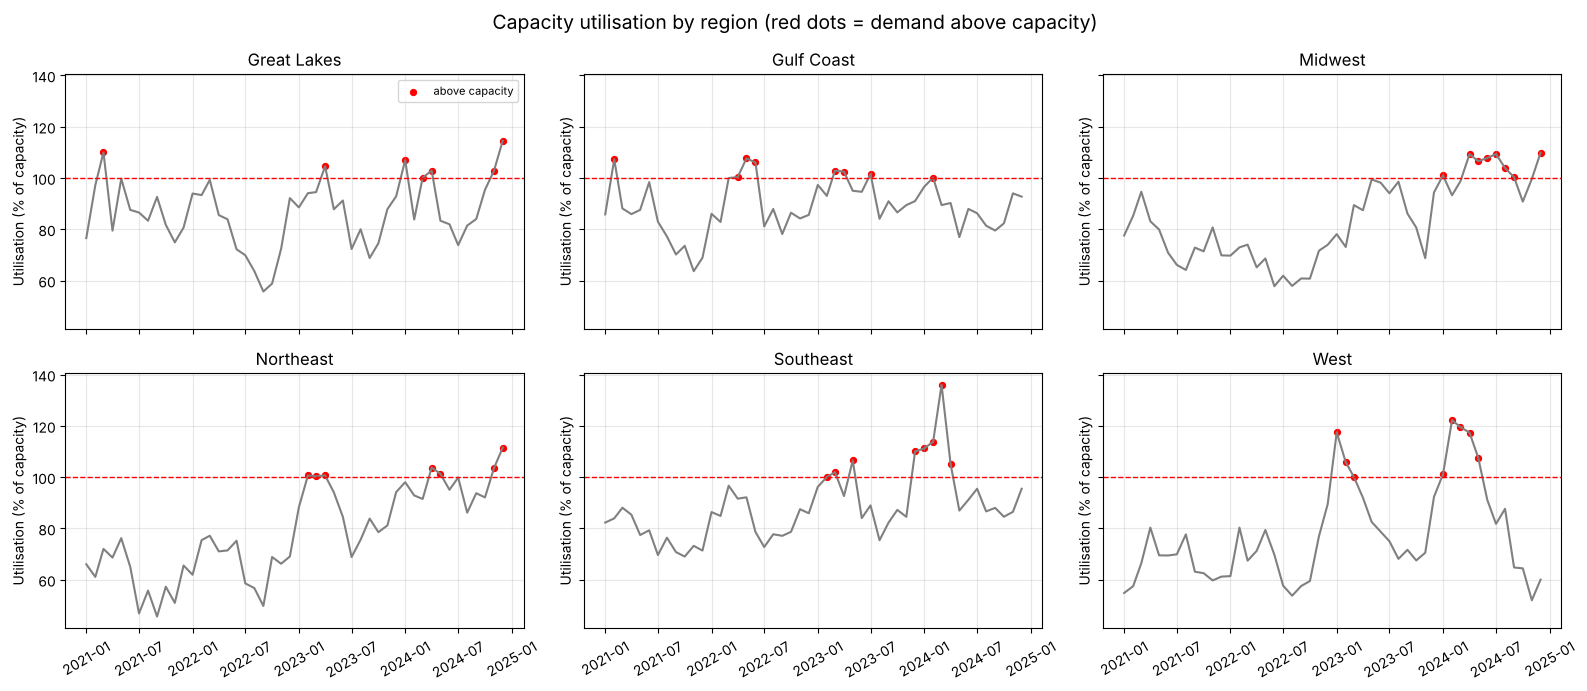

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True, sharey=True)

for ax, region in zip(axes.flat, regions):
    d = df[df["region"] == region]
    over = d["utilisation"] > 1
    ax.plot(d["date"], d["utilisation"] * 100, color="grey")
    ax.scatter(d.loc[over, "date"], d.loc[over, "utilisation"] * 100, color="red", s=18, label="above capacity")
    ax.axhline(100, color="red", linestyle="--", linewidth=1)
    ax.set_title(region)
    ax.set_ylabel("Utilisation (% of capacity)")
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(fontsize=8)
fig.suptitle("Capacity utilisation by region (red dots = demand above capacity)", fontsize=14)
plt.tight_layout()
plt.show()

In [43]:
# share of months where demand exceeded capacity, by year
over_capacity = df.assign(above=df["utilisation"] > 1).pivot_table(
    index="region", columns="year", values="above", aggfunc="mean") * 100
over_capacity.round(0)

year,2021,2022,2023,2024
region,,,,
Great Lakes,8.00,0.00,8.00,42.00
Gulf Coast,8.00,25.00,25.00,8.00
Midwest,0.00,0.00,0.00,67.00
Northeast,0.00,0.00,25.00,33.00
Southeast,0.00,0.00,33.00,33.00
West,0.00,0.00,25.00,42.00


**What we see**
- Demand above capacity was rare in 2021 but common by 2024. Share of 2024 months above capacity:
  - Midwest 67%
  - Great Lakes 42%
  - West 42%
  - Northeast 33%
  - Southeast 33%
  - Gulf Coast 8%
- The biggest spikes line up with low prices or promotions: Southeast reached 136% in March 2024 (promotion plus our lowest price against a high competitor price), and West went over 120% in early 2023 and early 2024 when its price was lowest.

**So what:** in many months we turned customers away. Demand above capacity cannot be sold, so pricing must use **tons sold = min(demand, capacity)**. It also suggests our prices are too low where plants are full.

## 14. Summary - what EDA tells us for modelling

| Finding | Evidence | What we do about it |
|---|---|---|
| Regions differ a lot in size, price level and growth | Gulf Coast is 2.5x Northeast; growth ranges from +6% to +60% | Analyse **region by region**; give each region its own level in the models (region fixed effects) |
| Clear upward trend | 12-month rolling averages rise in all regions | Explain it with drivers (price, economy) rather than a blind time trend |
| Same seasonal shape everywhere | Jan-May above trend, Jul-Nov below (about +/-13%) | Add **month-of-year effects** |
| Demand is persistent | Lag-1 autocorrelation 0.5-0.8 | Use "same as last month" as a baseline; check model residuals for autocorrelation |
| Demand is price-sensitive | Raw elasticity about -2 within regions; -3.0 if pooled (misleading) | Estimate elasticity **within regions** with controls (Step 3) |
| Price and the economy move together | Correlation down to -0.80 | Always include the **industrial index** next to price |
| Promotions help modestly | About +3% to +8% vs trend; not price cuts | Keep `promo_flag` as a control |
| Competitor price is a weak driver | Correlation -0.20 to +0.33 | Keep as a control, not a headline |
| Plants are getting full | 33-67% of 2024 months above capacity in five regions | Pricing uses **tons sold = min(demand, capacity)**; full plants suggest room to raise prices |